 EDA

 Imports

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import chi2_contingency

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 150)
sns.set(style="whitegrid")

def shape_report(label, frame):
    print(f"[{label}] shape = {frame.shape[0]:,} rows x {frame.shape[1]} columns")


 Load data

In [ ]:
df = pd.read_csv("/content/diabetic_data.csv")
shape_report("Raw data loaded", df)


[Raw data loaded] shape = 55,226 rows x 50 columns


In [ ]:
df.head()


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55226 entries, 0 to 55225
Data columns (total 50 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   encounter_id              55226 non-null  int64 
 1   patient_nbr               55226 non-null  int64 
 2   race                      55226 non-null  object
 3   gender                    55226 non-null  object
 4   age                       55226 non-null  object
 5   weight                    55226 non-null  object
 6   admission_type_id         55226 non-null  int64 
 7   discharge_disposition_id  55226 non-null  int64 
 8   admission_source_id       55226 non-null  int64 
 9   time_in_hospital          55226 non-null  int64 
 10  payer_code                55226 non-null  object
 11  medical_specialty         55226 non-null  object
 12  num_lab_procedures        55226 non-null  int64 
 13  num_procedures            55226 non-null  int64 
 14  num_medications       

Standardize missing-value placeholders

In [ ]:
before = df.isnull().sum()
print("Missing values BEFORE placeholder conversion (looks artificially clean):")
print(before[before > 0])


Missing values BEFORE placeholder conversion (looks artificially clean):
max_glu_serum               50535
A1Cresult                   46975
glyburide                       1
tolbutamide                     1
pioglitazone                    1
rosiglitazone                   1
acarbose                        1
miglitol                        1
troglitazone                    1
tolazamide                      1
examide                         1
citoglipton                     1
insulin                         1
glyburide-metformin             1
glipizide-metformin             1
glimepiride-pioglitazone        1
metformin-rosiglitazone         1
metformin-pioglitazone          1
change                          1
diabetesMed                     1
readmitted                      1
dtype: int64


In [ ]:
df = df.replace(["?", "None", "-"], np.nan)

missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({"missing": missing, "pct": missing_pct})
print("Missing values AFTER placeholder conversion:")
missing_summary[missing_summary["missing"] > 0].sort_values("pct", ascending=False)


Missing values AFTER placeholder conversion:


,missing,pct
weight,53257,96.43
max_glu_serum,50535,91.51
A1Cresult,46975,85.06
payer_code,34177,61.89
medical_specialty,20594,37.29
race,1279,2.32
diag_3,1142,2.07
diag_2,279,0.51
diag_1,11,0.02
glyburide,1,0.00


 Duplicate rows and repeated patients

In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique patients:", df['patient_nbr'].nunique(), "of", len(df), "total encounters")
print("Patients with more than one encounter:", (df['patient_nbr'].value_counts() > 1).sum())


Exact duplicate rows: 0
Unique patients: 42010 of 55226 total encounters
Patients with more than one encounter: 8099


Decode the coded categorical IDs

In [ ]:
table_names = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']

ids = pd.read_csv(
    "/content/IDS_mapping.csv", header=None, names=["id", "description"],
    keep_default_na=False, na_values=[""]
)
starts = ids[ids["id"].isin(table_names)].index.tolist() + [len(ids)]

id_maps = {}
for i in range(len(starts) - 1):
    name = ids.loc[starts[i], "id"]
    block = ids.iloc[starts[i] + 1: starts[i + 1]].dropna()
    block = block[block["id"] != ""]
    block["id"] = block["id"].astype(float).astype(int)
    id_maps[name] = block.set_index("id")["description"].to_dict()

for col in table_names:
    df[col + '_desc'] = df[col].map(id_maps[col])

shape_report("After decoding IDs (+3 descriptive columns)", df)


[After decoding IDs (+3 descriptive columns)] shape = 55,226 rows x 53 columns


In [ ]:
expired_mask = df['discharge_disposition_id_desc'].str.contains('Expired', case=False, na=False)
hospice_mask = df['discharge_disposition_id_desc'].str.contains('Hospice', case=False, na=False)
print(f"Encounters ending in patient death: {expired_mask.sum()} ({expired_mask.mean()*100:.2f}%)")
print(f"Encounters discharged to hospice:   {hospice_mask.sum()} ({hospice_mask.mean()*100:.2f}%)")
print(f"Combined (will be excluded in preprocessing, matching the paper): {(expired_mask | hospice_mask).sum()}")


Encounters ending in patient death: 960 (1.74%)
Encounters discharged to hospice:   288 (0.52%)
Combined (will be excluded in preprocessing, matching the paper): 1244


High-missingness columns

In [ ]:
df['max_glu_serum'] = df['max_glu_serum'].fillna('Missing')
df['A1Cresult'] = df['A1Cresult'].fillna('Missing')

HIGH_MISSING_THRESHOLD = 90
high_missing_cols = missing_summary[missing_summary['pct'] > HIGH_MISSING_THRESHOLD].index.tolist()
high_missing_cols = [c for c in high_missing_cols if c not in ['max_glu_serum', 'A1Cresult']]
print("Columns dropped (>90% missing, no informative 'not tested' reading):", high_missing_cols)

df_clean = df.drop(columns=high_missing_cols)

for col in ['payer_code', 'medical_specialty', 'race']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('Missing')

shape_report("After high-missingness handling", df_clean)


Columns dropped (>90% missing, no informative 'not tested' reading): ['weight']
[After high-missingness handling] shape = 55,226 rows x 52 columns


Classify columns by role (computed AFTER df_clean is final)

In [ ]:
id_cols = ['encounter_id', 'patient_nbr']
coded_categorical_cols = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
desc_cols = [c + '_desc' for c in coded_categorical_cols]
target_col = 'readmitted'

true_numeric_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns.difference(
    id_cols + coded_categorical_cols
).tolist()

cat_cols = df_clean.select_dtypes(include=['object']).columns.difference(
    [target_col] + desc_cols
).tolist()

print("Numeric columns:", true_numeric_cols)
print("\nCategorical columns:", cat_cols)
assert 'weight' not in cat_cols


Numeric columns: ['num_lab_procedures', 'num_medications', 'num_procedures', 'number_diagnoses', 'number_emergency', 'number_inpatient', 'number_outpatient', 'time_in_hospital']

Categorical columns: ['A1Cresult', 'acarbose', 'acetohexamide', 'age', 'change', 'chlorpropamide', 'citoglipton', 'diabetesMed', 'diag_1', 'diag_2', 'diag_3', 'examide', 'gender', 'glimepiride', 'glimepiride-pioglitazone', 'glipizide', 'glipizide-metformin', 'glyburide', 'glyburide-metformin', 'insulin', 'max_glu_serum', 'medical_specialty', 'metformin', 'metformin-pioglitazone', 'metformin-rosiglitazone', 'miglitol', 'nateglinide', 'payer_code', 'pioglitazone', 'race', 'repaglinide', 'rosiglitazone', 'tolazamide', 'tolbutamide', 'troglitazone']


 Descriptive statistics

In [ ]:
df_clean[true_numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
num_lab_procedures,55226.0,42.441930,19.202709,1.0,31.0,43.0,56.0,129.0
num_medications,55226.0,15.371981,8.144807,1.0,10.0,14.0,19.0,81.0
num_procedures,55226.0,1.358491,1.678671,0.0,0.0,1.0,2.0,6.0
number_diagnoses,55226.0,6.972929,2.018137,1.0,5.0,7.0,9.0,9.0
number_emergency,55226.0,0.131152,0.638029,0.0,0.0,0.0,0.0,42.0
number_inpatient,55226.0,0.587911,1.210215,0.0,0.0,0.0,1.0,21.0
number_outpatient,55226.0,0.235016,0.886933,0.0,0.0,0.0,0.0,36.0
time_in_hospital,55226.0,4.544472,3.078132,1.0,2.0,4.0,6.0,14.0


In [ ]:
df_clean[cat_cols].describe().T


,count,unique,top,freq
A1Cresult,55226,4,Missing,46975
acarbose,55225,4,No,55072
acetohexamide,55226,2,No,55225
age,55226,10,[70-80),14437
change,55225,2,No,32486
chlorpropamide,55226,4,No,55156
citoglipton,55225,1,No,55225
diabetesMed,55225,2,Yes,41253
diag_1,55215,650,414,4108
diag_2,54947,651,428,3852


 Frequency analysis

In [ ]:
cardinality = df_clean[cat_cols].nunique().sort_values(ascending=False)
print("Cardinality per categorical column (this is what drives sparsity after one-hot encoding):")
cardinality


Cardinality per categorical column (this is what drives sparsity after one-hot encoding):


,0
diag_3,687
diag_2,651
diag_1,650
medical_specialty,68
payer_code,16
age,10
race,6
rosiglitazone,4
acarbose,4
A1Cresult,4


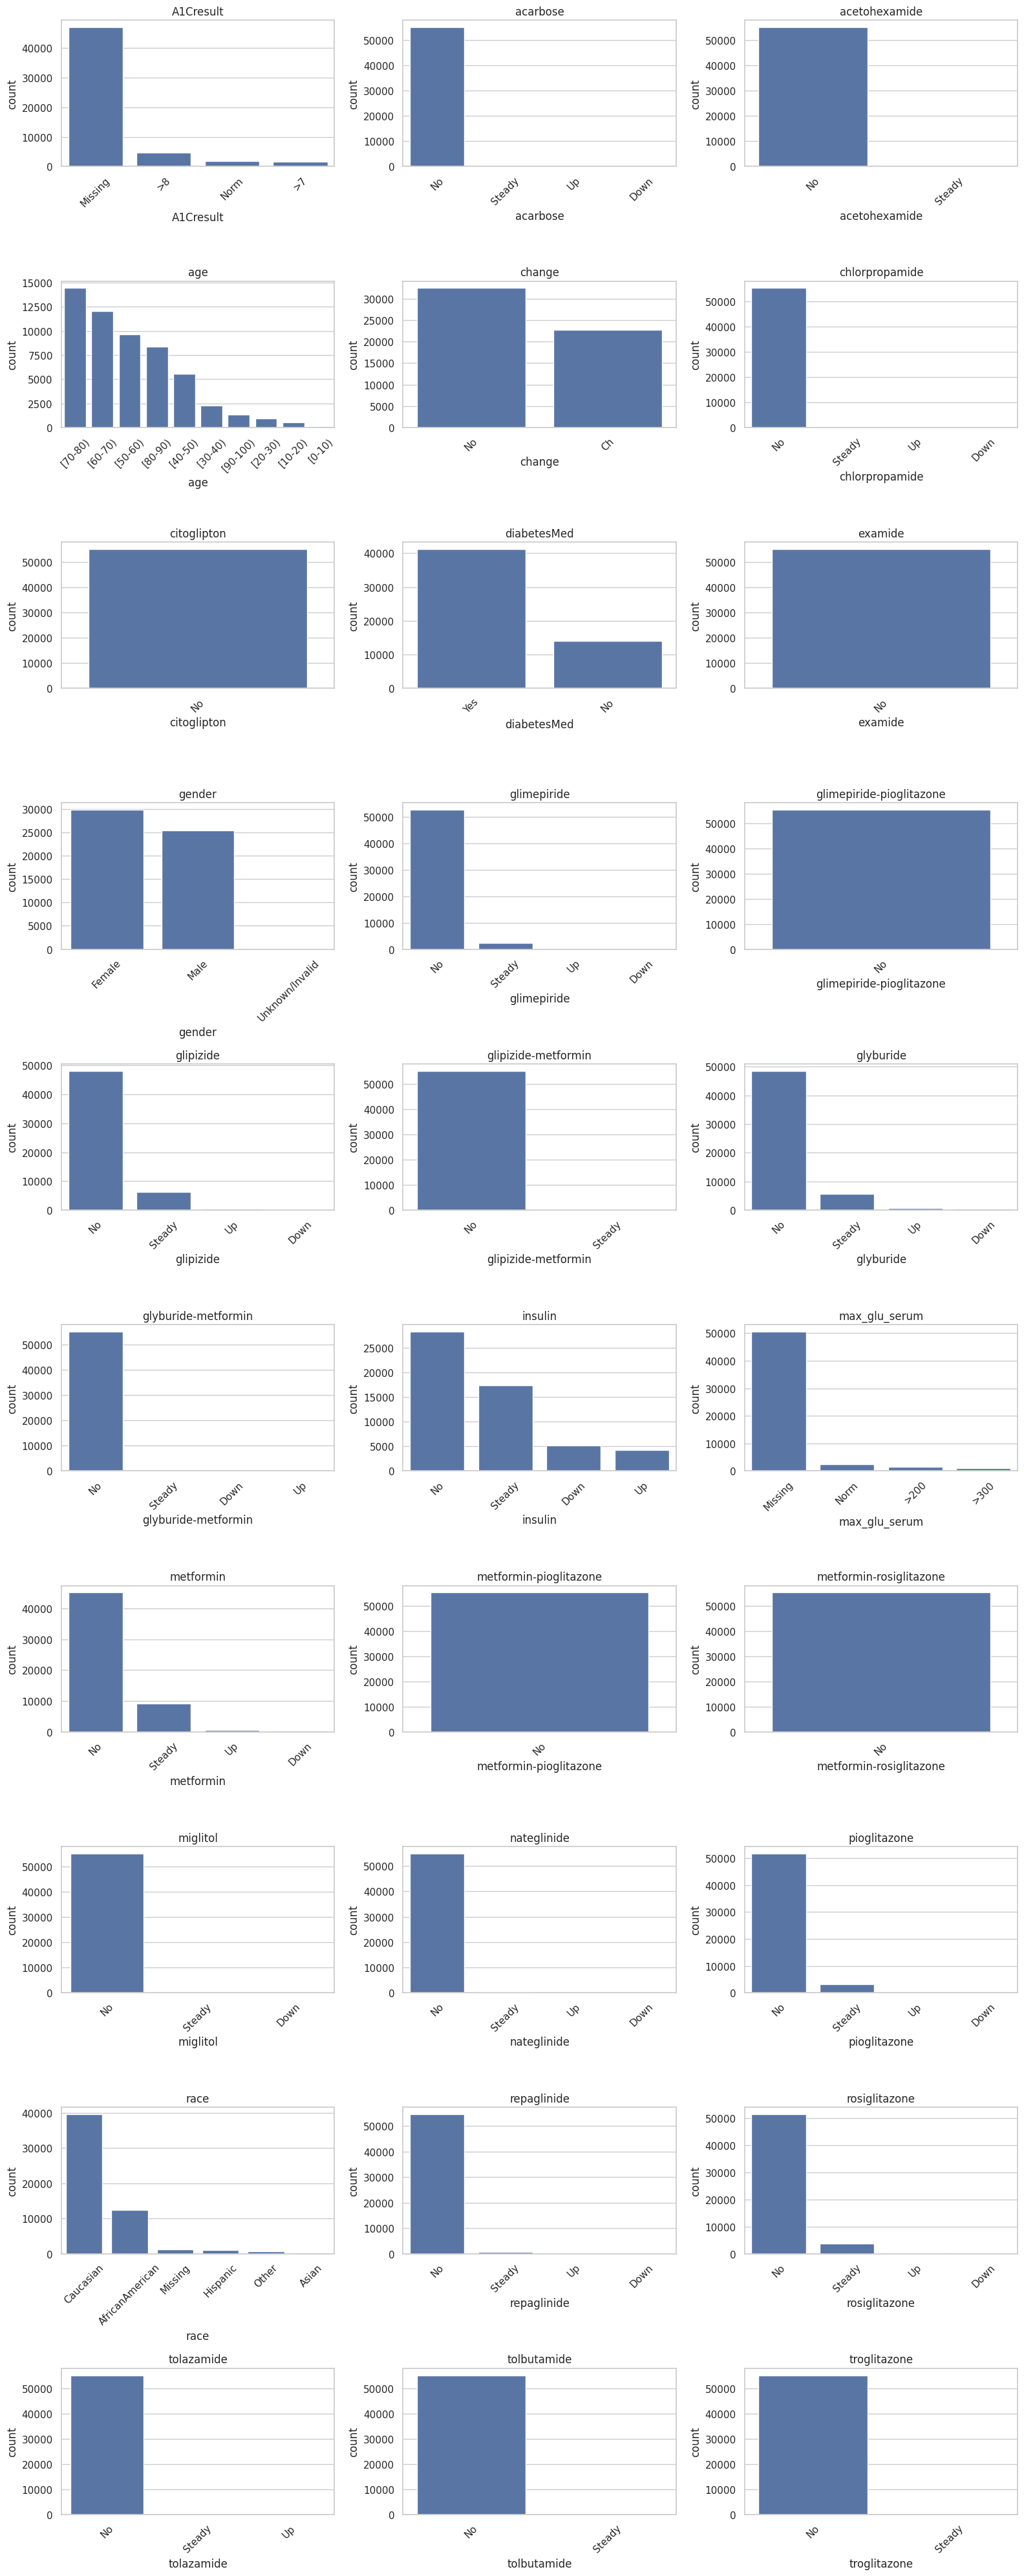

In [ ]:
low_card_cats = [c for c in cat_cols if df_clean[c].nunique() <= 10]
fig, axes = plt.subplots(nrows=(len(low_card_cats)+2)//3, ncols=3, figsize=(16, 4*((len(low_card_cats)+2)//3)))
axes = axes.flatten()
for ax, col in zip(axes, low_card_cats):
    order = df_clean[col].value_counts().index
    sns.countplot(x=col, data=df_clean, order=order, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
for ax in axes[len(low_card_cats):]:
    ax.axis('off')
plt.tight_layout()
plt.show()


 Variance (numeric features)

In [ ]:
variance = df_clean[true_numeric_cols].var().sort_values(ascending=False)
cv = (df_clean[true_numeric_cols].std() / df_clean[true_numeric_cols].mean()).sort_values(ascending=False)
pd.DataFrame({'variance': variance, 'coefficient_of_variation': cv})


,variance,coefficient_of_variation
num_lab_procedures,368.744052,0.452447
num_medications,66.337880,0.529848
num_procedures,2.817938,1.235689
number_diagnoses,4.072875,0.289424
number_emergency,0.407081,4.864808
number_inpatient,1.464621,2.058499
number_outpatient,0.786650,3.773923
time_in_hospital,9.474899,0.677336


 Normal-distribution check

In [ ]:
skew_kurt = pd.DataFrame({
    'skew': df_clean[true_numeric_cols].skew(),
    'kurtosis': df_clean[true_numeric_cols].kurt()
}).sort_values('skew', ascending=False)
skew_kurt


,skew,kurtosis
number_emergency,15.789178,593.042114
number_outpatient,8.739900,169.154568
number_inpatient,3.760836,22.807429
num_medications,1.481626,4.062791
num_procedures,1.255700,0.717268
time_in_hospital,1.068153,0.595317
num_lab_procedures,-0.136255,-0.232438
number_diagnoses,-0.584262,-0.774668


In [ ]:
for col in true_numeric_cols:
    sample = df_clean[col].dropna().sample(min(5000, df_clean[col].dropna().shape[0]), random_state=0)
    stat, p = stats.shapiro(sample)
    print(f"{col}: Shapiro-Wilk p = {p:.5f} {'(reject normality)' if p < 0.05 else ''}")


num_lab_procedures: Shapiro-Wilk p = 0.00000 (reject normality)
num_medications: Shapiro-Wilk p = 0.00000 (reject normality)
num_procedures: Shapiro-Wilk p = 0.00000 (reject normality)
number_diagnoses: Shapiro-Wilk p = 0.00000 (reject normality)
number_emergency: Shapiro-Wilk p = 0.00000 (reject normality)
number_inpatient: Shapiro-Wilk p = 0.00000 (reject normality)
number_outpatient: Shapiro-Wilk p = 0.00000 (reject normality)
time_in_hospital: Shapiro-Wilk p = 0.00000 (reject normality)


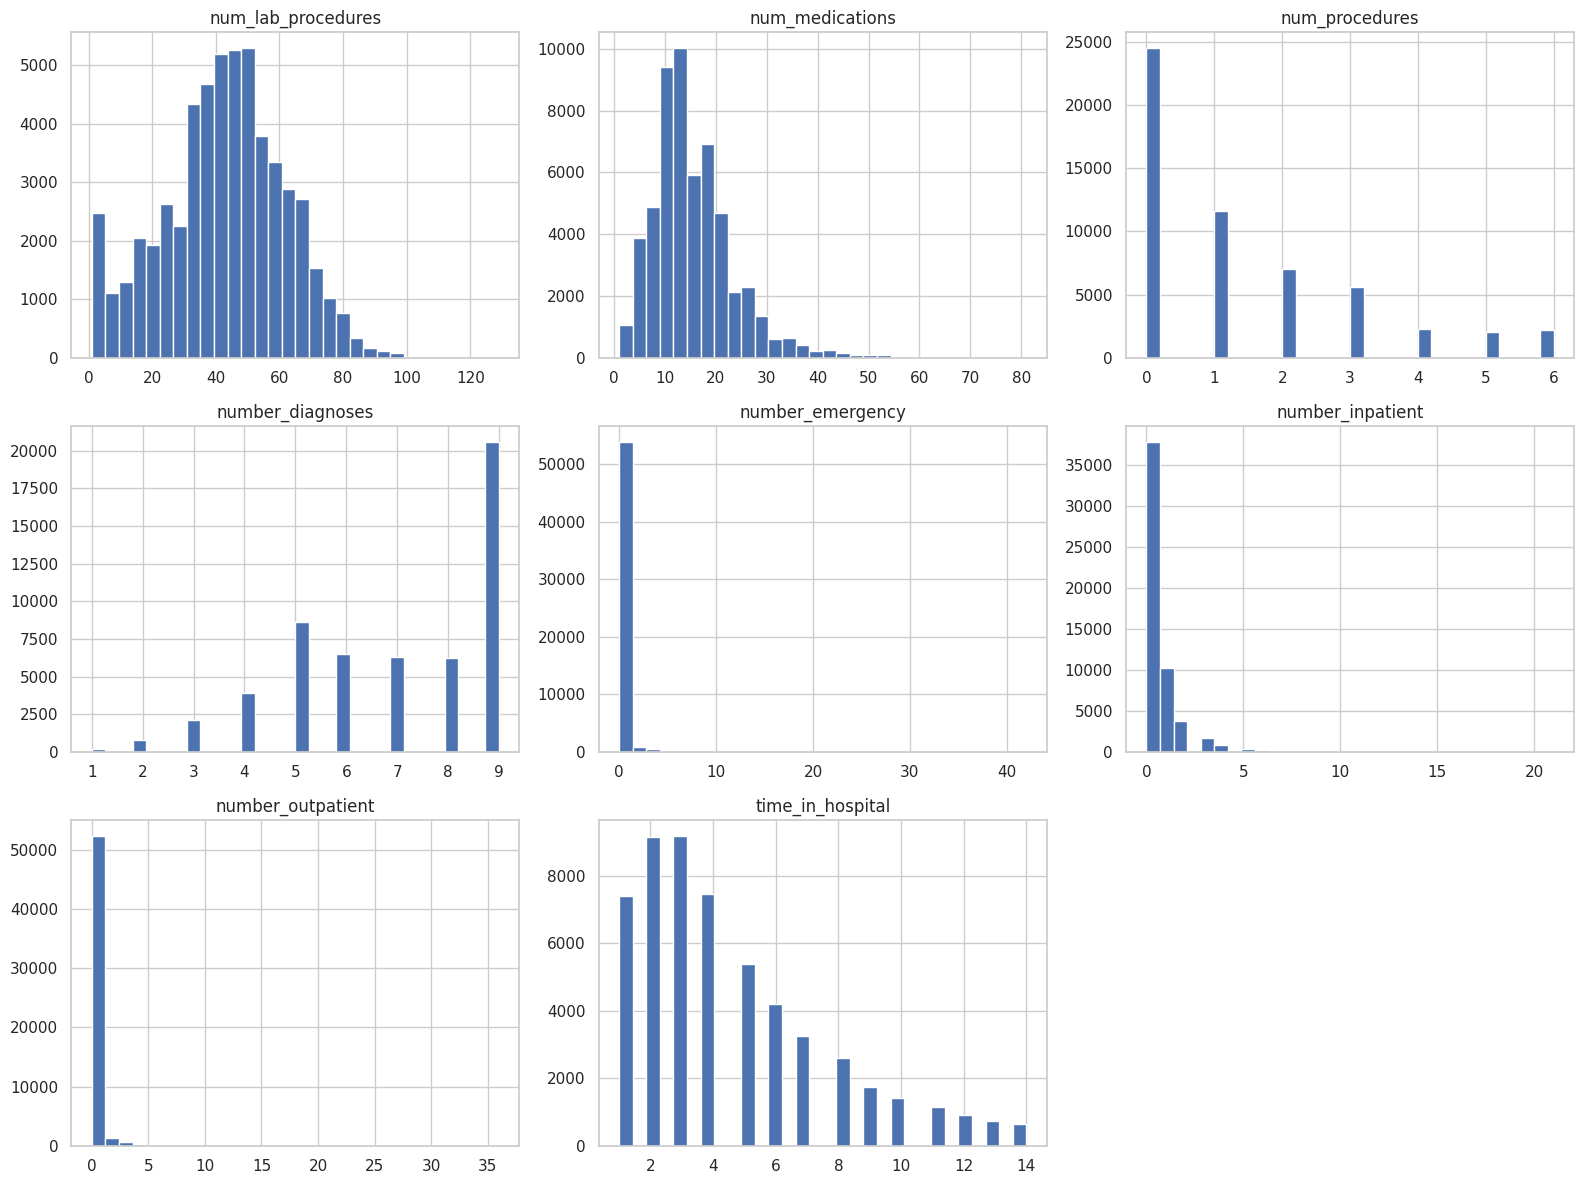

In [ ]:
df_clean[true_numeric_cols].hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()


 Collinearity (numeric <-> numeric)

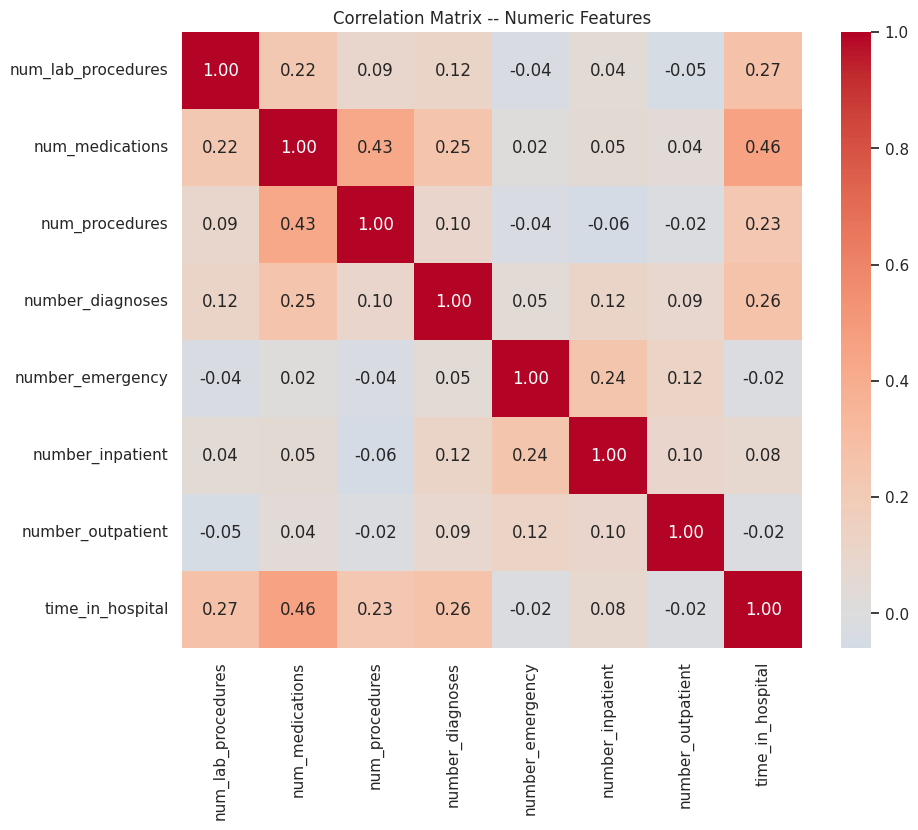

In [ ]:
corr = df_clean[true_numeric_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title("Correlation Matrix -- Numeric Features")
plt.show()


In [ ]:
high_corr = np.where(np.abs(corr.values) > 0.7)
pairs = [(corr.index[i], corr.columns[j], round(corr.values[i, j], 3)) for i, j in zip(*high_corr) if i < j]
print("Pairs with |correlation| > 0.7:", pairs if pairs else "none")

try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    vif_data = df_clean[true_numeric_cols].dropna()
    vif = pd.DataFrame({
        'feature': true_numeric_cols,
        'VIF': [variance_inflation_factor(vif_data.values, i) for i in range(len(true_numeric_cols))]
    }).sort_values('VIF', ascending=False)
    print(vif)
except ImportError:
    print("statsmodels not installed -- run `pip install statsmodels` to compute VIF.")


Pairs with |correlation| > 0.7: none
              feature       VIF
3    number_diagnoses  7.112328
1     num_medications  6.821590
0  num_lab_procedures  5.426659
7    time_in_hospital  4.306221
2      num_procedures  2.046874
5    number_inpatient  1.349902
4    number_emergency  1.123190
6   number_outpatient  1.104403


 Interdependence (categorical <-> categorical, categorical <-> target)

Excluded constant columns (no variation to measure): ['citoglipton', 'examide', 'glimepiride-pioglitazone', 'metformin-pioglitazone', 'metformin-rosiglitazone']


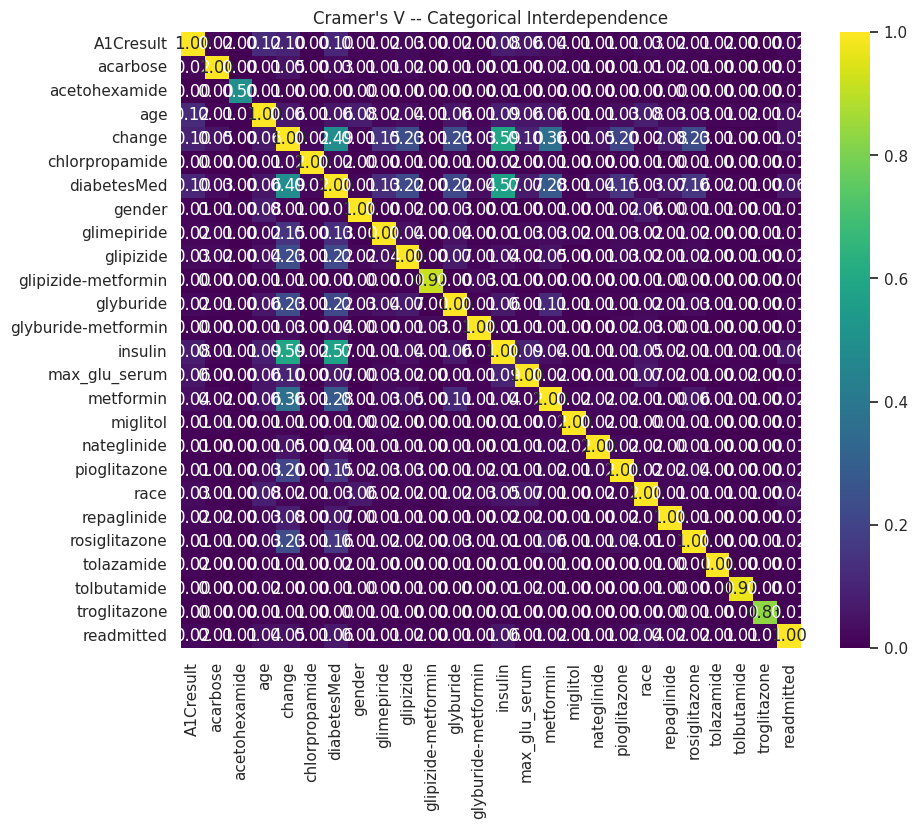

In [ ]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    if min(ct.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(ct)[0]
    n = ct.sum().sum()
    return (chi2 / (n * (min(ct.shape) - 1))) ** 0.5

constant_cols = [c for c in cat_cols if df_clean[c].nunique() < 2]
print("Excluded constant columns (no variation to measure):", constant_cols)

interdep_cols = [c for c in cat_cols if 2 <= df_clean[c].nunique() <= 15] + [target_col]
cramers_matrix = pd.DataFrame(index=interdep_cols, columns=interdep_cols, dtype=float)
for a in interdep_cols:
    for b in interdep_cols:
        cramers_matrix.loc[a, b] = cramers_v(df_clean[a], df_clean[b])

plt.figure(figsize=(10, 8))
sns.heatmap(cramers_matrix.astype(float), annot=True, fmt=".2f", cmap='viridis')
plt.title("Cramer's V -- Categorical Interdependence")
plt.show()


 Target variable: `readmitted`

In [ ]:
print(df_clean[target_col].value_counts())
print()
print(df_clean[target_col].value_counts(normalize=True).round(3))


readmitted
NO     29447
>30    19455
<30     6323
Name: count, dtype: int64

readmitted
NO     0.533
>30    0.352
<30    0.114
Name: proportion, dtype: float64


 Diagnosis codes -- grouping

Applied to the raw ICD-9 strings, before any encoding.

In [ ]:
def categorize_diag(diag):
    if pd.isna(diag):
        return 'Missing'
    diag = str(diag)
    if diag.startswith('V') or diag.startswith('E'):
        return 'Other'
    try:
        val = float(diag)
    except ValueError:
        return 'Other'
    if 390 <= val <= 459 or val == 785:
        return 'Circulatory'
    elif 460 <= val <= 519 or val == 786:
        return 'Respiratory'
    elif 520 <= val <= 579 or val == 787:
        return 'Digestive'
    elif int(val) == 250:
        return 'Diabetes'
    elif 800 <= val <= 999:
        return 'Injury'
    elif 710 <= val <= 739:
        return 'Musculoskeletal'
    elif 580 <= val <= 629 or val == 788:
        return 'Genitourinary'
    elif 140 <= val <= 239:
        return 'Neoplasms'
    else:
        return 'Other'

for col in ['diag_1', 'diag_2', 'diag_3']:
    print(f"{col}: {df_clean[col].nunique()} raw unique codes  ->  ", end="")
    df_clean[col + '_group'] = df_clean[col].apply(categorize_diag)
    group_col = col + '_group'
    print(f"{df_clean[group_col].nunique()} grouped categories")

shape_report("After diagnosis grouping (+3 columns)", df_clean)
df_clean['diag_1_group'].value_counts()


diag_1: 650 raw unique codes  ->  10 grouped categories
diag_2: 651 raw unique codes  ->  10 grouped categories
diag_3: 687 raw unique codes  ->  10 grouped categories
[After diagnosis grouping (+3 columns)] shape = 55,226 rows x 55 columns


,count
diag_1_group,
Circulatory,17486
Other,9647
Respiratory,7454
Digestive,5042
Diabetes,5000
Injury,3607
Musculoskeletal,2648
Genitourinary,2435
Neoplasms,1896


Medication columns — near-constant check

In [ ]:
med_cols = [c for c in cat_cols if df_clean[c].isin(['No', 'Steady', 'Up', 'Down']).any()]
med_summary = pd.DataFrame({col: df_clean[col].value_counts(normalize=True) for col in med_cols}).T.fillna(0).round(3)
med_summary['dominant_class_pct'] = med_summary.max(axis=1)
med_summary.sort_values('dominant_class_pct', ascending=False)


,Ch,Down,No,Steady,Up,Yes,dominant_class_pct
acetohexamide,0.000,0.000,1.000,0.000,0.000,0.000,1.000
glimepiride-pioglitazone,0.000,0.000,1.000,0.000,0.000,0.000,1.000
citoglipton,0.000,0.000,1.000,0.000,0.000,0.000,1.000
examide,0.000,0.000,1.000,0.000,0.000,0.000,1.000
troglitazone,0.000,0.000,1.000,0.000,0.000,0.000,1.000
miglitol,0.000,0.000,1.000,0.000,0.000,0.000,1.000
metformin-pioglitazone,0.000,0.000,1.000,0.000,0.000,0.000,1.000
metformin-rosiglitazone,0.000,0.000,1.000,0.000,0.000,0.000,1.000
glipizide-metformin,0.000,0.000,1.000,0.000,0.000,0.000,1.000
tolbutamide,0.000,0.000,1.000,0.000,0.000,0.000,1.000


 Preprocessing

In [ ]:
model_df = df_clean.copy()
shape_report("Start of preprocessing", model_df)


[Start of preprocessing] shape = 55,226 rows x 55 columns


 Exclude expired AND hospice encounters

The paper excludes both groups. An earlier version of this notebook only excluded 'Expired' -- fixed here to match the paper exactly.

In [ ]:
before_n = len(model_df)
exclude_mask = (
    model_df['discharge_disposition_id_desc'].str.contains('Expired', case=False, na=False) |
    model_df['discharge_disposition_id_desc'].str.contains('Hospice', case=False, na=False)
)
model_df = model_df[~exclude_mask]
print(f"Excluded {before_n - len(model_df)} expired/hospice encounters")
shape_report("After excluding expired/hospice", model_df)


Excluded 1244 expired/hospice encounters
[After excluding expired/hospice] shape = 53,982 rows x 55 columns


 Remove ambiguous / missing readmission labels

In [ ]:
before_n = len(model_df)
model_df = model_df[model_df['readmitted'].notna() & model_df['readmitted'].isin(['NO', '>30', '<30'])]
print(f"Removed {before_n - len(model_df)} rows with missing/ambiguous readmission labels")
shape_report("After removing ambiguous target rows", model_df)


Removed 1 rows with missing/ambiguous readmission labels
[After removing ambiguous target rows] shape = 53,981 rows x 55 columns


Encode the target (30-day readmission, matching the paper's framing)

In [ ]:
model_df['readmitted_binary'] = model_df['readmitted'].map({'<30': 1, '>30': 0, 'NO': 0}).astype(int)
print(model_df['readmitted_binary'].value_counts())
print(model_df['readmitted_binary'].value_counts(normalize=True).round(4))


readmitted_binary
0    47680
1     6301
Name: count, dtype: int64
readmitted_binary
0    0.8833
1    0.1167
Name: proportion, dtype: float64


Age: bucket string -> numeric

In [ ]:
model_df['age'] = model_df['age'].str.extract(r'(\d+)').astype(int)


Mean imputation for missing numeric values (per the paper)



In [ ]:
numeric_missing = model_df[true_numeric_cols].isnull().sum()
cols_needing_imputation = numeric_missing[numeric_missing > 0].index.tolist()
print("Numeric columns with missing values:", cols_needing_imputation if cols_needing_imputation else "none")

for col in cols_needing_imputation:
    mean_val = model_df[col].mean()
    model_df[col] = model_df[col].fillna(mean_val)
    print(f"  {col}: imputed {numeric_missing[col]} values with mean = {mean_val:.2f}")

print("Remaining numeric missing values:", model_df[true_numeric_cols].isnull().sum().sum())


Numeric columns with missing values: none
Remaining numeric missing values: 0


 Drop columns no longer needed for modeling

In [ ]:
patient_ids = model_df['patient_nbr']

model_df = model_df.drop(columns=['diag_1', 'diag_2', 'diag_3'])
model_df = model_df.drop(columns=coded_categorical_cols)
model_df = model_df.drop(columns=['readmitted'])
model_df = model_df.drop(columns=id_cols)

shape_report("After dropping redundant/ID columns", model_df)


[After dropping redundant/ID columns] shape = 53,981 rows x 47 columns


Reduce sparsity: group rare categories BEFORE one-hot encoding



In [ ]:
RARE_CATEGORY_THRESHOLD = 0.01  # categories under 1% of rows get grouped into 'Other'

nominal_cols_preview = model_df.select_dtypes(include=['object']).columns.tolist()

def group_rare_categories(series, threshold=RARE_CATEGORY_THRESHOLD):
    freq = series.value_counts(normalize=True)
    keep = freq[freq >= threshold].index
    return series.where(series.isin(keep), 'Other')

cardinality_before = model_df[nominal_cols_preview].nunique()
for col in nominal_cols_preview:
    model_df[col] = group_rare_categories(model_df[col])
cardinality_after = model_df[nominal_cols_preview].nunique()

sparsity_report = pd.DataFrame({
    'categories_before': cardinality_before,
    'categories_after': cardinality_after,
    'dummy_cols_saved': cardinality_before - cardinality_after
}).sort_values('dummy_cols_saved', ascending=False)
print(sparsity_report)
print(f"\nTotal dummy columns saved by rare-category grouping: {sparsity_report['dummy_cols_saved'].sum()}")


                               categories_before  categories_after  dummy_cols_saved
medical_specialty                             68                13                55
discharge_disposition_id_desc                 21                10                11
payer_code                                    16                 9                 7
admission_source_id_desc                      13                 8                 5
nateglinide                                    4                 2                 2
admission_type_id_desc                         8                 6                 2
glyburide-metformin                            4                 2                 2
acarbose                                       4                 2                 2
chlorpropamide                                 4                 2                 2
tolazamide                                     3                 2                 1
pioglitazone                                   4                 

One-hot encode remaining categorical variables

In [ ]:
nominal_cols = model_df.select_dtypes(include=['object']).columns.tolist()
print("One-hot encoding:", nominal_cols)

X = pd.get_dummies(model_df.drop(columns=['readmitted_binary']), columns=nominal_cols, drop_first=True)
y = model_df['readmitted_binary']

shape_report("After one-hot encoding (this is X, before the target column)", X)
print(f"Sparsity: {(X.select_dtypes(include='bool').eq(False).sum().sum() + X.select_dtypes(include='uint8').eq(0).sum().sum()) / (X.shape[0]*X.shape[1]) * 100:.1f}% of one-hot cells are 0 (this is expected sparsity, not missing data)")


One-hot encoding: ['race', 'gender', 'payer_code', 'medical_specialty', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'admission_type_id_desc', 'discharge_disposition_id_desc', 'admission_source_id_desc', 'diag_1_group', 'diag_2_group', 'diag_3_group']
[After one-hot encoding (this is X, before the target column)] shape = 53,981 rows x 118 columns
Sparsity: 82.4% of one-hot cells are 0 (this is expected sparsity, not missing data)


 Stratified, patient-aware 80/20 split



In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups=patient_ids))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train: {X_train.shape[0]:,} rows  |  Test: {X_test.shape[0]:,} rows  |  {X_train.shape[1]} features")
print(f"Train positive rate: {y_train.mean():.4f}  |  Test positive rate: {y_test.mean():.4f}  (stratification preserved)")

train_patients = set(patient_ids.iloc[train_idx])
test_patients = set(patient_ids.iloc[test_idx])
print(f"Patient overlap between train/test: {len(train_patients & test_patients)} (should be 0)")


Train: 43,165 rows  |  Test: 10,816 rows  |  118 features
Train positive rate: 0.1151  |  Test positive rate: 0.1231  (stratification preserved)
Patient overlap between train/test: 0 (should be 0)


Standardize continuous variables (per the paper)

In [ ]:
from sklearn.preprocessing import StandardScaler

numeric_feature_cols = [c for c in true_numeric_cols if c in X_train.columns] + ['age']
numeric_feature_cols = list(dict.fromkeys(numeric_feature_cols))

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_feature_cols] = scaler.fit_transform(X_train[numeric_feature_cols])
X_test_scaled[numeric_feature_cols] = scaler.transform(X_test[numeric_feature_cols])
print("Scaled columns:", numeric_feature_cols)


Scaled columns: ['num_lab_procedures', 'num_medications', 'num_procedures', 'number_diagnoses', 'number_emergency', 'number_inpatient', 'number_outpatient', 'time_in_hospital', 'age']


Class imbalance: class weighting (per the paper)



In [ ]:
from sklearn.utils.class_weight import compute_class_weight

class_weights_arr = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight_dict = {0: class_weights_arr[0], 1: class_weights_arr[1]}
print("Class weights:", class_weight_dict)
print(f"(the minority 'readmitted' class is weighted ~{class_weight_dict[1]/class_weight_dict[0]:.1f}x higher than the majority class)")


Class weights: {0: np.float64(0.5650608718418642), 1: np.float64(4.342555331991952)}
(the minority 'readmitted' class is weighted ~7.7x higher than the majority class)


Preprocessing summary table (for the report)

A single table tracing row/column count through every stage above.

In [ ]:
preprocessing_summary = pd.DataFrame([
    {"stage": "Raw data", "rows": 101766, "columns": 50},
    {"stage": "After ID decoding (+3)", "rows": df.shape[0], "columns": df.shape[1]},
    {"stage": "After high-missingness handling (df_clean)", "rows": df_clean.shape[0], "columns": df_clean.shape[1]},
    {"stage": "After excluding expired/hospice", "rows": model_df.shape[0], "columns": model_df.shape[1]},
    {"stage": "After one-hot encoding (X)", "rows": X.shape[0], "columns": X.shape[1]},
    {"stage": "Train split", "rows": X_train.shape[0], "columns": X_train.shape[1]},
    {"stage": "Test split", "rows": X_test.shape[0], "columns": X_test.shape[1]},
])
preprocessing_summary


,stage,rows,columns
0,Raw data,101766,50
1,After ID decoding (+3),55226,53
2,After high-missingness handling (df_clean),55226,55
3,After excluding expired/hospice,53981,47
4,After one-hot encoding (X),53981,118
5,Train split,43165,118
6,Test split,10816,118


In [ ]:
selected_features = X_train.columns.tolist()

X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]
X_train_scaled_selected = X_train_scaled[selected_features]
X_test_scaled_selected = X_test_scaled[selected_features]

In [ ]:
# Moved earlier (before PCA/Lasso fitting) -- feature selection must only ever see sub-train rows,
# never the validation rows, or validation AUC becomes slightly optimistic.
from sklearn.model_selection import StratifiedGroupKFold

train_patient_ids = patient_ids.iloc[train_idx]   # reuses train_idx from the main 80/20 split, done earlier

val_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=123)
subtrain_idx, val_idx = next(val_splitter.split(X_train, y_train, groups=train_patient_ids))

print(f"Sub-train: {len(subtrain_idx):,} rows | Internal validation: {len(val_idx):,} rows")

# Confirm no leakage anywhere across the three-way split
sub_patients = set(train_patient_ids.iloc[subtrain_idx])
val_patients = set(train_patient_ids.iloc[val_idx])
test_patients = set(patient_ids.iloc[test_idx])
print(f"Sub-train/val overlap: {len(sub_patients & val_patients)} | Val/test overlap: {len(val_patients & test_patients)}")

Sub-train: 34,556 rows | Internal validation: 8,609 rows
Sub-train/val overlap: 0 | Val/test overlap: 0


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_train_scaled_selected.iloc[subtrain_idx])  # fit ONLY on sub-train rows -- validation rows must not influence component selection

explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

pca_summary = pd.DataFrame({
    'component': range(1, len(explained_var) + 1),
    'explained_variance_ratio': explained_var,
    'cumulative_variance': cumulative_var
})
print(pca_summary.head(15))

n_pcs_80 = int(np.argmax(cumulative_var >= 0.80) + 1)
n_pcs_90 = int(np.argmax(cumulative_var >= 0.90) + 1)
print(f"\nComponents needed for 80% of total variance: {n_pcs_80}")
print(f"Components needed for 90% of total variance: {n_pcs_90}")
print(f"(out of {X_train_scaled_selected.shape[1]} original selected features)")


    component  explained_variance_ratio  cumulative_variance
0           1                  0.132188             0.132188
1           2                  0.087024             0.219212
2           3                  0.078989             0.298201
3           4                  0.070192             0.368392
4           5                  0.057175             0.425567
5           6                  0.049020             0.474587
6           7                  0.044504             0.519091
7           8                  0.043572             0.562663
8           9                  0.036278             0.598941
9          10                  0.028089             0.627030
10         11                  0.022781             0.649811
11         12                  0.020765             0.670576
12         13                  0.017790             0.688367
13         14                  0.016571             0.704938
14         15                  0.015609             0.720547

Components needed for 8

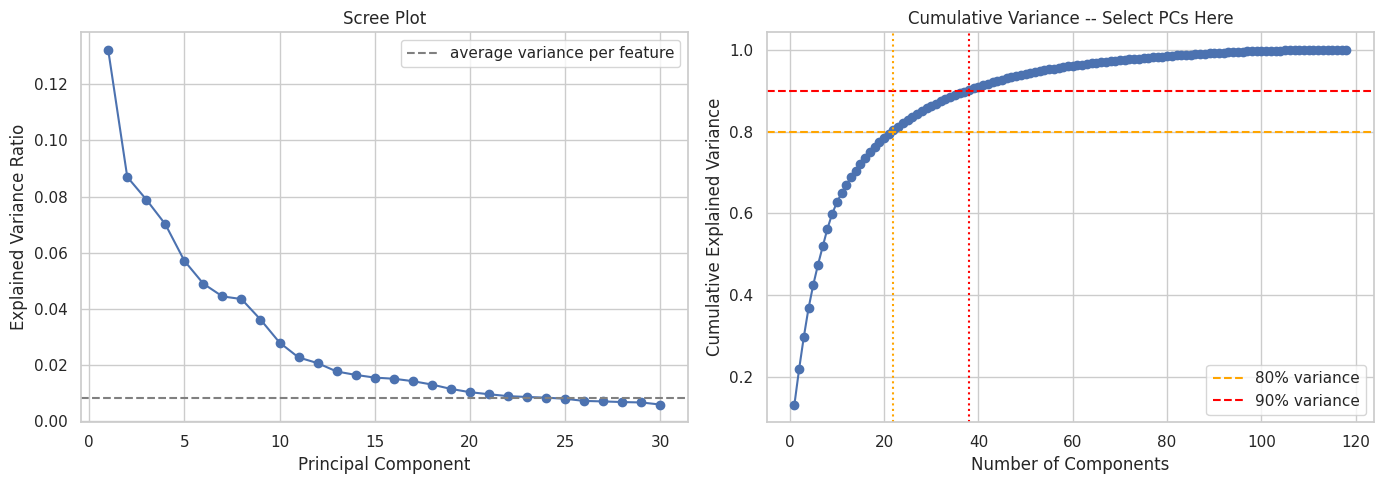

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(pca_summary['component'].iloc[:30], pca_summary['explained_variance_ratio'].iloc[:30], marker='o')
axes[0].axhline(1 / X_train_scaled_selected.shape[1], color='gray', linestyle='--', label='average variance per feature')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot')
axes[0].legend()

axes[1].plot(pca_summary['component'], pca_summary['cumulative_variance'], marker='o')
axes[1].axhline(0.80, color='orange', linestyle='--', label='80% variance')
axes[1].axhline(0.90, color='red', linestyle='--', label='90% variance')
axes[1].axvline(n_pcs_80, color='orange', linestyle=':')
axes[1].axvline(n_pcs_90, color='red', linestyle=':')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title('Cumulative Variance -- Select PCs Here')
axes[1].legend()

plt.tight_layout()
plt.show()


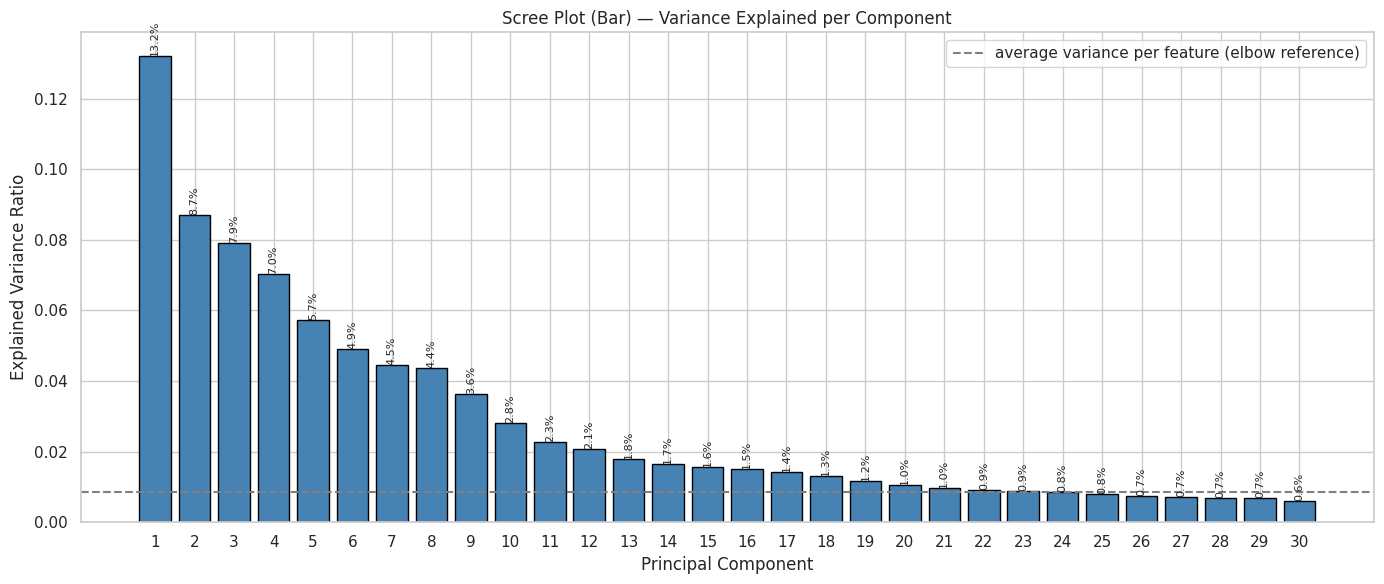

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))

N_SHOW = 30
subset = pca_summary.iloc[:N_SHOW]

bars = ax.bar(subset['component'], subset['explained_variance_ratio'], color='steelblue', edgecolor='black')

for bar, val in zip(bars, subset['explained_variance_ratio']):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height(),
        f"{val*100:.1f}%",
        ha='center', va='bottom', fontsize=8, rotation=90
    )

ax.axhline(1 / X_train_scaled_selected.shape[1], color='gray', linestyle='--',
           label='average variance per feature (elbow reference)')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('Scree Plot (Bar) — Variance Explained per Component')
ax.set_xticks(subset['component'])
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold

Cs = np.logspace(-4, 2, 20)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lasso_cv = LogisticRegressionCV(
    penalty='l1', solver='liblinear', Cs=Cs, cv=inner_cv,
    scoring='roc_auc',
    class_weight=class_weight_dict, random_state=42, max_iter=2000
)
lasso_cv.fit(X_train_scaled_selected.iloc[subtrain_idx], y_train.iloc[subtrain_idx])  # fit ONLY on sub-train rows -- same reasoning as PCA above

lasso_coefs = pd.Series(
    np.abs(lasso_cv.coef_[0]), index=X_train_scaled_selected.columns
).sort_values(ascending=False)
n_nonzero = int((lasso_coefs > 0).sum())
print(f"Lasso kept {n_nonzero} of {len(lasso_coefs)} features nonzero (best C = {lasso_cv.C_[0]:.4g})")

Lasso kept 76 of 118 features nonzero (best C = 0.06952)


In [ ]:
# lasso_coefs should be a Series of |coefficient| values, sorted descending
abs_coefs = lasso_coefs.abs().sort_values(ascending=False)

# cumulative share of total importance as you add features one by one
lasso_cumulative = abs_coefs.cumsum() / abs_coefs.sum()

# number of features needed to reach 80% / 50% of total importance
n_feats_80 = (lasso_cumulative >= 0.80).idxmax()  # index label
n_feats_80 = lasso_cumulative.index.get_loc(n_feats_80) + 1  # convert to count

n_feats_50 = (lasso_cumulative >= 0.50).idxmax()
n_feats_50 = lasso_cumulative.index.get_loc(n_feats_50) + 1

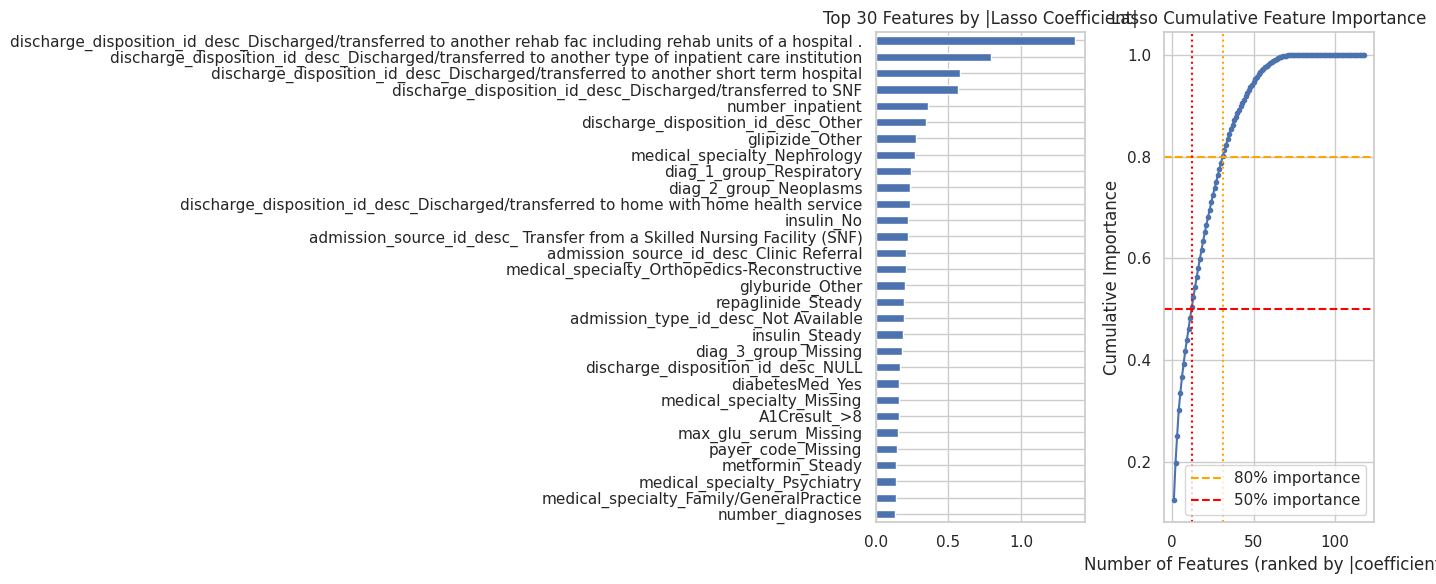

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

lasso_coefs.head(30).sort_values().plot(kind='barh', ax=axes[0])
axes[0].set_title('Top 30 Features by |Lasso Coefficient|')

axes[1].plot(range(1, len(lasso_cumulative) + 1), lasso_cumulative.values, marker='.')
axes[1].axhline(0.80, color='orange', linestyle='--', label='80% importance')
axes[1].axhline(0.50, color='red', linestyle='--', label='50% importance')
axes[1].axvline(n_feats_80, color='orange', linestyle=':')
axes[1].axvline(n_feats_50, color='red', linestyle=':')
axes[1].set_xlabel('Number of Features (ranked by |coefficient|)')
axes[1].set_ylabel('Cumulative Importance')
axes[1].set_title('Lasso Cumulative Feature Importance')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
N_COMPONENTS = 25  # scree flattens after this point (your data: 22 PCs hit 80% variance, 38 hit 90%)

X_train_pca_full = pca.transform(X_train_scaled_selected)   # reuses the already-fitted `pca` from cell 69 -- no leakage
X_test_pca_full = pca.transform(X_test_scaled_selected)

pca_cols = [f'PC{i+1}' for i in range(N_COMPONENTS)]
X_train_pca = pd.DataFrame(X_train_pca_full[:, :N_COMPONENTS], columns=pca_cols, index=X_train_scaled_selected.index)
X_test_pca = pd.DataFrame(X_test_pca_full[:, :N_COMPONENTS], columns=pca_cols, index=X_test_scaled_selected.index)

print(f"PCA feature set: {N_COMPONENTS} components, explaining {pca.explained_variance_ratio_[:N_COMPONENTS].sum()*100:.1f}% of variance")

PCA feature set: 25 components, explaining 82.9% of variance


In [ ]:
lasso_features_80 = lasso_cumulative.index[:n_feats_80].tolist()
lasso_features_50 = lasso_cumulative.index[:n_feats_50].tolist()

print(f"80% feature list ({len(lasso_features_80)} features):\n{lasso_features_80}")
print(f"\n50% feature list ({len(lasso_features_50)} features):\n{lasso_features_50}")

80% feature list (31 features):
['discharge_disposition_id_desc_Discharged/transferred to another rehab fac including rehab units of a hospital .', 'discharge_disposition_id_desc_Discharged/transferred to another type of inpatient care institution', 'discharge_disposition_id_desc_Discharged/transferred to another short term hospital', 'discharge_disposition_id_desc_Discharged/transferred to SNF', 'number_inpatient', 'discharge_disposition_id_desc_Other', 'glipizide_Other', 'medical_specialty_Nephrology', 'diag_1_group_Respiratory', 'diag_2_group_Neoplasms', 'discharge_disposition_id_desc_Discharged/transferred to home with home health service', 'insulin_No', 'admission_source_id_desc_ Transfer from a Skilled Nursing Facility (SNF)', 'admission_source_id_desc_Clinic Referral', 'medical_specialty_Orthopedics-Reconstructive', 'glyburide_Other', 'repaglinide_Steady', 'admission_type_id_desc_Not Available', 'insulin_Steady', 'diag_3_group_Missing', 'discharge_disposition_id_desc_NULL', 'dia

In [ ]:
X_train_lasso = X_train_selected[lasso_features_80]
X_test_lasso = X_test_selected[lasso_features_80]
X_train_lasso_scaled = X_train_scaled_selected[lasso_features_80]
X_test_lasso_scaled = X_test_scaled_selected[lasso_features_80]

print(f"Lasso feature set: {len(lasso_features_80)} features (80% cumulative importance)")

Lasso feature set: 31 features (80% cumulative importance)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_split(model, X, y):
    pred = model.predict(X)
    score = model.predict_proba(X)[:, 1]
    return dict(
        accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred), f1=f1_score(y, pred, zero_division=0), auc=roc_auc_score(y, score)
    )

def train_and_evaluate(feature_set_name, X_tr, y_tr, X_val, y_val, X_te, y_te, class_weight_dict):
    models = {
        'Logistic Regression': LogisticRegression(class_weight=class_weight_dict, max_iter=2000, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=300, class_weight=class_weight_dict, random_state=42, n_jobs=-1),
    }
    try:
        from xgboost import XGBClassifier
        models['XGBoost'] = XGBClassifier(
            scale_pos_weight=class_weight_dict[1] / class_weight_dict[0],
            eval_metric='auc', random_state=42, n_jobs=-1
        )
    except ImportError:
        print("xgboost not installed -- run `pip install xgboost` to include it")

    rows = []
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        val_metrics = evaluate_split(model, X_val, y_val)
        test_metrics = evaluate_split(model, X_te, y_te)
        rows.append({'feature_set': feature_set_name, 'model': name, 'split': 'internal_validation', **val_metrics})
        rows.append({'feature_set': feature_set_name, 'model': name, 'split': 'external_test', **test_metrics})
        print(f"{feature_set_name} -- {name}: done")
    return pd.DataFrame(rows)

In [ ]:
# PCA pipeline
X_subtrain_pca, X_val_pca = X_train_pca.iloc[subtrain_idx], X_train_pca.iloc[val_idx]
y_subtrain, y_val = y_train.iloc[subtrain_idx], y_train.iloc[val_idx]
results_pca = train_and_evaluate('PCA (25 components)', X_subtrain_pca, y_subtrain, X_val_pca, y_val, X_test_pca, y_test, class_weight_dict)

# Lasso pipeline (using scaled version, since Logistic Regression needs scaling; RF/XGBoost don't care either way)
X_subtrain_lasso, X_val_lasso = X_train_lasso_scaled.iloc[subtrain_idx], X_train_lasso_scaled.iloc[val_idx]
results_lasso = train_and_evaluate('Lasso (80% importance)', X_subtrain_lasso, y_subtrain, X_val_lasso, y_val, X_test_lasso_scaled, y_test, class_weight_dict)

combined_results = pd.concat([results_pca, results_lasso], ignore_index=True).round(4)
combined_results.sort_values(['feature_set', 'model', 'split'])

PCA (25 components) -- Logistic Regression: done
PCA (25 components) -- Random Forest: done
PCA (25 components) -- XGBoost: done
Lasso (80% importance) -- Logistic Regression: done
Lasso (80% importance) -- Random Forest: done
Lasso (80% importance) -- XGBoost: done


,feature_set,model,split,accuracy,precision,recall,f1,auc
7,Lasso (80% importance),Logistic Regression,external_test,0.6616,0.1902,0.5372,0.2809,0.6618
6,Lasso (80% importance),Logistic Regression,internal_validation,0.6728,0.1824,0.5367,0.2723,0.6601
9,Lasso (80% importance),Random Forest,external_test,0.7563,0.1621,0.2352,0.1919,0.5618
8,Lasso (80% importance),Random Forest,internal_validation,0.7648,0.1435,0.2138,0.1718,0.5437
11,Lasso (80% importance),XGBoost,external_test,0.6690,0.1893,0.5147,0.2768,0.6387
10,Lasso (80% importance),XGBoost,internal_validation,0.6796,0.1730,0.4786,0.2542,0.6280
1,PCA (25 components),Logistic Regression,external_test,0.6452,0.1834,0.5455,0.2745,0.6415
0,PCA (25 components),Logistic Regression,internal_validation,0.6520,0.1707,0.5316,0.2584,0.6340
3,PCA (25 components),Random Forest,external_test,0.8768,0.3333,0.0008,0.0015,0.6304
2,PCA (25 components),Random Forest,internal_validation,0.8857,0.0000,0.0000,0.0000,0.6148


In [ ]:
print(f"Lasso feature set ready: {len(lasso_features_80)} features")

Lasso feature set ready: 31 features


In [ ]:
pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 21.3 MB/s eta 0:00:00


In [ ]:

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)  # keeps 500-trial output readable

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score

MODEL_KEYS = [
    'linear_l2', 'linear_l1', 'linear_elasticnet',
    'tree_decision', 'tree_rf', 'tree_extra',
    'boost_xgb', 'boost_lgbm', 'boost_ada',
    'nn_shallow', 'nn_medium', 'nn_deep',
]

def build_model(trial, key, class_weight_dict):
    if key == 'linear_l2':
        return LogisticRegression(penalty='l2', C=trial.suggest_float('C', 1e-3, 1e2, log=True),
                                   class_weight=class_weight_dict, max_iter=2000, random_state=42)
    if key == 'linear_l1':
        return LogisticRegression(penalty='l1', solver='liblinear', C=trial.suggest_float('C', 1e-3, 1e2, log=True),
                                   class_weight=class_weight_dict, max_iter=2000, random_state=42)
    if key == 'linear_elasticnet':
        return LogisticRegression(penalty='elasticnet', solver='saga',
                                   C=trial.suggest_float('C', 1e-3, 1e2, log=True),
                                   l1_ratio=trial.suggest_float('l1_ratio', 0.0, 1.0),
                                   class_weight=class_weight_dict, max_iter=3000, random_state=42)
    if key == 'tree_decision':
        return DecisionTreeClassifier(max_depth=trial.suggest_int('max_depth', 3, 20),
                                       min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 50),
                                       class_weight=class_weight_dict, random_state=42)
    if key == 'tree_rf':
        return RandomForestClassifier(n_estimators=trial.suggest_int('n_estimators', 100, 500),
                                       max_depth=trial.suggest_int('max_depth', 3, 20),
                                       min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 20),
                                       class_weight=class_weight_dict, random_state=42, n_jobs=-1)
    if key == 'tree_extra':
        return ExtraTreesClassifier(n_estimators=trial.suggest_int('n_estimators', 100, 500),
                                     max_depth=trial.suggest_int('max_depth', 3, 20),
                                     min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 20),
                                     class_weight=class_weight_dict, random_state=42, n_jobs=-1)
    if key == 'boost_xgb':
        try:
            from xgboost import XGBClassifier
            return XGBClassifier(n_estimators=trial.suggest_int('n_estimators', 100, 500),
                                  max_depth=trial.suggest_int('max_depth', 3, 10),
                                  learning_rate=trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
                                  scale_pos_weight=class_weight_dict[1] / class_weight_dict[0],
                                  eval_metric='auc', random_state=42, n_jobs=-1)
        except ImportError:
            return GradientBoostingClassifier(n_estimators=trial.suggest_int('n_estimators', 100, 300),
                                               max_depth=trial.suggest_int('max_depth', 3, 8),
                                               learning_rate=trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
                                               random_state=42)
    if key == 'boost_lgbm':
        try:
            from lightgbm import LGBMClassifier
            return LGBMClassifier(n_estimators=trial.suggest_int('n_estimators', 100, 500),
                                   num_leaves=trial.suggest_int('num_leaves', 15, 127),
                                   learning_rate=trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
                                   class_weight=class_weight_dict, random_state=42, n_jobs=-1, verbose=-1)
        except ImportError:
            return GradientBoostingClassifier(n_estimators=trial.suggest_int('n_estimators', 100, 300),
                                               max_depth=trial.suggest_int('max_depth', 3, 8),
                                               random_state=42)
    if key == 'boost_ada':
        return AdaBoostClassifier(n_estimators=trial.suggest_int('n_estimators', 50, 300),
                                   learning_rate=trial.suggest_float('learning_rate', 1e-3, 2.0, log=True),
                                   random_state=42)
    if key == 'nn_shallow':
        return MLPClassifier(hidden_layer_sizes=(trial.suggest_int('h1', 16, 128),),
                              alpha=trial.suggest_float('alpha', 1e-5, 1e-1, log=True), max_iter=500, random_state=42)
    if key == 'nn_medium':
        return MLPClassifier(hidden_layer_sizes=(trial.suggest_int('h1', 32, 128), trial.suggest_int('h2', 16, 64)),
                              alpha=trial.suggest_float('alpha', 1e-5, 1e-1, log=True), max_iter=500, random_state=42)
    if key == 'nn_deep':
        return MLPClassifier(hidden_layer_sizes=(trial.suggest_int('h1', 32, 128), trial.suggest_int('h2', 16, 64), trial.suggest_int('h3', 8, 32)),
                              alpha=trial.suggest_float('alpha', 1e-5, 1e-1, log=True), max_iter=500, random_state=42)
    raise ValueError(key)

def make_objective(key, X_tr, y_tr, X_val, y_val, class_weight_dict):
    def objective(trial):
        model = build_model(trial, key, class_weight_dict)
        model.fit(X_tr, y_tr)
        proba = model.predict_proba(X_val)[:, 1]
        return roc_auc_score(y_val, proba)
    return objective

In [ ]:
N_TRIALS_TOTAL = 500
TRIALS_PER_MODEL = N_TRIALS_TOTAL // len(MODEL_KEYS)
print(f"{TRIALS_PER_MODEL} trials/model x {len(MODEL_KEYS)} models = {TRIALS_PER_MODEL * len(MODEL_KEYS)} total trials")

def run_all_studies(label, X_tr, y_tr, X_val, y_val, X_te, y_te, class_weight_dict):
    results = []
    best_models = {}
    for key in MODEL_KEYS:

        study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
        start_time = time.time()   # <-- new
        study.optimize(
            make_objective(key, X_tr, y_tr, X_val, y_val, class_weight_dict),
            n_trials=TRIALS_PER_MODEL,
            callbacks=[make_logging_callback(label, key, start_time)],   # <-- new
            show_progress_bar=False
        )


        best_model = build_model(optuna.trial.FixedTrial(study.best_params), key, class_weight_dict)
        best_model.fit(X_tr, y_tr)
        best_models[key] = best_model

        test_proba = best_model.predict_proba(X_te)[:, 1]
        test_auc = roc_auc_score(y_te, test_proba)

        results.append({'balancing': label, 'model': key, 'best_params': study.best_params,
                         'val_auc': study.best_value, 'test_auc': test_auc})
        print(f"[{label}] {key}: val_auc={study.best_value:.4f}, test_auc={test_auc:.4f}")

    return pd.DataFrame(results), best_models

41 trials/model x 12 models = 492 total trials


In [ ]:
import time, csv, os
from datetime import datetime

LOG_FILE = "tuning_log.csv"

def init_log():
    if not os.path.exists(LOG_FILE):
        with open(LOG_FILE, "w", newline="") as f:
            csv.writer(f).writerow(["timestamp", "balancing", "model", "trial_number", "trial_auc", "best_auc_so_far", "elapsed_sec"])
    print(f"Logging to: {os.path.abspath(LOG_FILE)}")

def log_row(balancing, model, trial_number, trial_auc, best_auc_so_far, start_time):
    elapsed = round(time.time() - start_time, 1)
    with open(LOG_FILE, "a", newline="") as f:
        csv.writer(f).writerow([datetime.now().strftime("%H:%M:%S"), balancing, model, trial_number,
                                 round(trial_auc, 4), round(best_auc_so_far, 4), elapsed])
    print(f"[{datetime.now().strftime('%H:%M:%S')}] {balancing} | {model:16s} | trial {trial_number:3d} | "
          f"AUC={trial_auc:.4f} | best={best_auc_so_far:.4f} | {elapsed:>6}s elapsed")

def make_logging_callback(balancing, model_key, start_time):
    def callback(study, trial):
        log_row(balancing, model_key, trial.number, trial.value, study.best_value, start_time)
    return callback

init_log()

Logging to: /content/tuning_log.csv


In [ ]:

results_no_smote, models_no_smote = run_all_studies(
    'class_weight_only',
    X_subtrain_lasso, y_subtrain, X_val_lasso, y_val, X_test_lasso_scaled, y_test, class_weight_dict
)

[19:54:37] class_weight_only | linear_l2        | trial   0 | AUC=0.6600 | best=0.6600 |    0.9s elapsed
[19:54:38] class_weight_only | linear_l2        | trial   1 | AUC=0.6600 | best=0.6600 |    1.8s elapsed
[19:54:39] class_weight_only | linear_l2        | trial   2 | AUC=0.6599 | best=0.6600 |    2.4s elapsed
[19:54:39] class_weight_only | linear_l2        | trial   3 | AUC=0.6601 | best=0.6601 |    2.8s elapsed
[19:54:39] class_weight_only | linear_l2        | trial   4 | AUC=0.6565 | best=0.6601 |    3.2s elapsed
[19:54:40] class_weight_only | linear_l2        | trial   5 | AUC=0.6564 | best=0.6601 |    3.7s elapsed
[19:54:40] class_weight_only | linear_l2        | trial   6 | AUC=0.6487 | best=0.6601 |    3.9s elapsed
[19:54:41] class_weight_only | linear_l2        | trial   7 | AUC=0.6600 | best=0.6601 |    4.6s elapsed
[19:54:41] class_weight_only | linear_l2        | trial   8 | AUC=0.6601 | best=0.6601 |    5.3s elapsed
[19:54:43] class_weight_only | linear_l2        | trial

In [ ]:
top3_no_smote = results_no_smote.sort_values('val_auc', ascending=False).head(3)['model'].tolist()


print("Top 3 (no SMOTE):", top3_no_smote)


Top 3 (no SMOTE): ['nn_shallow', 'nn_medium', 'boost_lgbm']


In [ ]:
def run_studies_for_keys(label, model_keys, n_trials_total, X_tr, y_tr, X_val, y_val, X_te, y_te, class_weight_dict):
    trials_per_model = n_trials_total // len(model_keys)
    print(f"[{label}] {trials_per_model} trials/model x {len(model_keys)} models = {trials_per_model * len(model_keys)} total")

    results = []
    best_models = {}
    for key in model_keys:
        study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
        start_time = time.time()
        study.optimize(
            make_objective(key, X_tr, y_tr, X_val, y_val, class_weight_dict),
            n_trials=trials_per_model,
            callbacks=[make_logging_callback(label, key, start_time)],
            show_progress_bar=False
        )
        best_model = build_model(optuna.trial.FixedTrial(study.best_params), key, class_weight_dict)
        best_model.fit(X_tr, y_tr)
        best_models[key] = best_model

        test_proba = best_model.predict_proba(X_te)[:, 1]
        test_auc = roc_auc_score(y_te, test_proba)
        results.append({'balancing': label, 'model': key, 'best_params': study.best_params,
                         'val_auc': study.best_value, 'test_auc': test_auc})

    return pd.DataFrame(results), best_models

In [ ]:
fine_results_no_smote, fine_models_no_smote = run_studies_for_keys(
    'class_weight_only_fine', top3_no_smote, 300,
    X_subtrain_lasso, y_subtrain, X_val_lasso, y_val, X_test_lasso_scaled, y_test, class_weight_dict
)

[class_weight_only_fine] 100 trials/model x 3 models = 300 total
[22:23:57] class_weight_only_fine | nn_shallow       | trial   0 | AUC=0.6653 | best=0.6653 |    6.1s elapsed
[22:25:53] class_weight_only_fine | nn_shallow       | trial   1 | AUC=0.6265 | best=0.6653 |  122.2s elapsed
[22:26:07] class_weight_only_fine | nn_shallow       | trial   2 | AUC=0.6534 | best=0.6653 |  136.2s elapsed
[22:26:13] class_weight_only_fine | nn_shallow       | trial   3 | AUC=0.6601 | best=0.6653 |  142.6s elapsed
[22:26:37] class_weight_only_fine | nn_shallow       | trial   4 | AUC=0.6346 | best=0.6653 |  166.8s elapsed
[22:26:43] class_weight_only_fine | nn_shallow       | trial   5 | AUC=0.6665 | best=0.6665 |  172.0s elapsed
[22:28:05] class_weight_only_fine | nn_shallow       | trial   6 | AUC=0.6139 | best=0.6665 |  253.9s elapsed
[22:28:26] class_weight_only_fine | nn_shallow       | trial   7 | AUC=0.6436 | best=0.6665 |  275.5s elapsed
[22:28:48] class_weight_only_fine | nn_shallow       | 

In [ ]:
# No SMOTE-NC branch exists in this notebook to concatenate against, so fine_results_no_smote IS the final table --
# the previous pd.concat([fine_results_no_smote]) was concatenating a single-item list, which is a no-op.
fine_results_no_smote.sort_values('test_auc', ascending=False)[['balancing', 'model', 'val_auc', 'test_auc', 'best_params']]

,balancing,model,val_auc,test_auc,best_params
2,class_weight_only_fine,boost_lgbm,0.667222,0.666958,"{'n_estimators': 228, 'num_leaves': 15, 'learn..."
1,class_weight_only_fine,nn_medium,0.666798,0.665684,"{'h1': 110, 'h2': 25, 'alpha': 0.0960715374438..."
0,class_weight_only_fine,nn_shallow,0.670407,0.665437,"{'h1': 16, 'alpha': 0.017736344094493182}"


In [ ]:
try:
    import tensorflow as tf
    from tensorflow.keras import layers, models, regularizers
    from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
    from tensorflow.keras.optimizers import Adam

    def build_ann(input_dim):
        model = models.Sequential([
            layers.Input(shape=(input_dim,)),

            layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),  # L2 regularization: penalizes large weights, fights overfitting
            layers.BatchNormalization(),   # stabilizes/speeds up training by normalizing activations between layers
            layers.Dropout(0.4),           # randomly disables 40% of neurons each step -- forces the network to not over-rely on any single one

            layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
            layers.BatchNormalization(),
            layers.Dropout(0.3),

            layers.Dense(32, activation='relu'),
            layers.Dropout(0.2),

            layers.Dense(1, activation='sigmoid')
        ])
        model.compile(
            optimizer=Adam(learning_rate=0.001),
            loss='binary_crossentropy',
            metrics=['AUC']
        )
        return model

    ann_model = build_ann(X_subtrain_lasso.shape[1])

    # Stop training once val_AUC stops improving, and roll back to the BEST epoch
    # (not just whatever epoch training happened to end on)
    early_stop = EarlyStopping(monitor='val_AUC', mode='max', patience=8, restore_best_weights=True)

    # Automatically shrinks the learning rate when progress stalls, letting the model
    # fine-tune with smaller steps instead of overshooting once it's close to a good solution
    reduce_lr = ReduceLROnPlateau(monitor='val_AUC', mode='max', factor=0.5, patience=4, min_lr=1e-6)

    history = ann_model.fit(
        X_subtrain_lasso, y_subtrain,
        validation_data=(X_val_lasso, y_val),
        epochs=100,                      # raised ceiling -- early stopping will cut it short automatically
        batch_size=64,                   # slightly larger batches: smoother gradient estimates, faster epochs
        class_weight=class_weight_dict,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )

    print(f"\nStopped at epoch {len(history.history['loss'])} (best epoch restored automatically)")

    def get_ann_predictions(X):
        proba = ann_model.predict(X, verbose=0).ravel()
        pred = (proba >= 0.5).astype(int)
        return pred, proba

except ImportError:
    print("tensorflow not installed -- run `pip install tensorflow` for the real Keras version above.")
    print("Falling back to a regularized sklearn MLPClassifier with its own built-in early stopping.")
    from sklearn.neural_network import MLPClassifier

    ann_model = MLPClassifier(
        hidden_layer_sizes=(128, 64, 32),
        alpha=1e-3,                      # L2 regularization strength (sklearn's equivalent of kernel_regularizer above)
        early_stopping=True,             # sklearn's built-in version of what EarlyStopping does above
        validation_fraction=0.15,
        n_iter_no_change=10,
        max_iter=300,
        random_state=42
    )
    ann_model.fit(X_subtrain_lasso, y_subtrain)

    def get_ann_predictions(X):
        proba = ann_model.predict_proba(X)[:, 1]
        pred = (proba >= 0.5).astype(int)
        return pred, proba

Epoch 1/100
540/540 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - AUC: 0.5811 - loss: 0.7446 - val_AUC: 0.6342 - val_loss: 0.6666 - learning_rate: 0.0010
Epoch 2/100
540/540 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.6283 - loss: 0.6873 - val_AUC: 0.6451 - val_loss: 0.6250 - learning_rate: 0.0010
Epoch 3/100
540/540 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.6463 - loss: 0.6755 - val_AUC: 0.6583 - val_loss: 0.6452 - learning_rate: 0.0010
Epoch 4/100
540/540 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.6468 - loss: 0.6736 - val_AUC: 0.6617 - val_loss: 0.6569 - learning_rate: 0.0010
Epoch 5/100
540/540 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.6602 - loss: 0.6681 - val_AUC: 0.6600 - val_loss: 0.6328 - learning_rate: 0.0010
Epoch 6/100
540/540 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.6658 - loss: 0.6649 - val_AUC: 0.6649 - val_loss: 0.6438 - learning_rate: 0.0010
Epoch 7/100
540/540 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.6691 - loss: 0.6630 - val_AUC: 0.6647 - val_loss: 0.6843 - learning_rate: 0.0010

In [ ]:
val_pred, val_proba = get_ann_predictions(X_val_lasso)
test_pred, test_proba = get_ann_predictions(X_test_lasso_scaled)

ann_val_metrics = {
    'accuracy': accuracy_score(y_val, val_pred), 'precision': precision_score(y_val, val_pred, zero_division=0),
    'recall': recall_score(y_val, val_pred), 'f1': f1_score(y_val, val_pred, zero_division=0),
    'auc': roc_auc_score(y_val, val_proba)
}
ann_test_metrics = {
    'accuracy': accuracy_score(y_test, test_pred), 'precision': precision_score(y_test, test_pred, zero_division=0),
    'recall': recall_score(y_test, test_pred), 'f1': f1_score(y_test, test_pred, zero_division=0),
    'auc': roc_auc_score(y_test, test_proba)
}

print("Improved ANN -- Internal Validation:", {k: round(v,4) for k,v in ann_val_metrics.items()})
print("Improved ANN -- External Test:", {k: round(v,4) for k,v in ann_test_metrics.items()})

Improved ANN -- Internal Validation: {'accuracy': 0.6492, 'precision': 0.1816, 'recall': 0.5916, 'f1': 0.2779, 'auc': np.float64(0.6682)}
Improved ANN -- External Test: {'accuracy': 0.6373, 'precision': 0.1905, 'recall': 0.5995, 'f1': 0.2892, 'auc': np.float64(0.6661)}


In [ ]:
import optuna
from sklearn.metrics import roc_auc_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

def build_ann_from_trial(trial, input_dim):
    from tensorflow.keras import layers, models, regularizers
    from tensorflow.keras.optimizers import Adam

    n_layers = trial.suggest_int('n_layers', 2, 4)
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5)
    l2_reg = trial.suggest_float('l2_reg', 1e-6, 1e-2, log=True)
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
    first_units = trial.suggest_categorical('first_units', [64, 128, 256])

    layer_list = [layers.Input(shape=(input_dim,))]
    units = first_units
    for i in range(n_layers):
        layer_list.append(layers.Dense(units, activation='relu', kernel_regularizer=regularizers.l2(l2_reg)))
        layer_list.append(layers.BatchNormalization())
        layer_list.append(layers.Dropout(dropout_rate))
        units = max(units // 2, 8)   # each layer roughly halves in width, floor at 8
    layer_list.append(layers.Dense(1, activation='sigmoid'))

    model = models.Sequential(layer_list)
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=['AUC'])
    return model

def ann_objective(trial):
    from tensorflow.keras.callbacks import EarlyStopping

    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])
    model = build_ann_from_trial(trial, X_subtrain_lasso.shape[1])

    early_stop = EarlyStopping(monitor='val_AUC', mode='max', patience=8, restore_best_weights=True)

    model.fit(
        X_subtrain_lasso, y_subtrain,
        validation_data=(X_val_lasso, y_val),
        epochs=100, batch_size=batch_size,
        class_weight=class_weight_dict,
        callbacks=[early_stop],
        verbose=0
    )

    val_proba = model.predict(X_val_lasso, verbose=0).ravel()
    return roc_auc_score(y_val, val_proba)

In [ ]:
N_ANN_TRIALS = 40

start_time = time.time()
ann_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))

ann_study.optimize(
    ann_objective,
    n_trials=N_ANN_TRIALS,
    callbacks=[make_logging_callback('ann_tuning', 'keras_ann', start_time)],
    show_progress_bar=False
)

print(f"Best val AUC: {ann_study.best_value:.4f}")
print(f"Best params: {ann_study.best_params}")

[01:12:36] ann_tuning | keras_ann        | trial   0 | AUC=0.6647 | best=0.6647 |   98.0s elapsed
[01:13:10] ann_tuning | keras_ann        | trial   1 | AUC=0.6674 | best=0.6674 |  131.3s elapsed
[01:14:36] ann_tuning | keras_ann        | trial   2 | AUC=0.6669 | best=0.6674 |  217.7s elapsed
[01:16:43] ann_tuning | keras_ann        | trial   3 | AUC=0.6699 | best=0.6699 |  344.1s elapsed
[01:17:50] ann_tuning | keras_ann        | trial   4 | AUC=0.6642 | best=0.6699 |  411.0s elapsed
[01:19:27] ann_tuning | keras_ann        | trial   5 | AUC=0.6665 | best=0.6699 |  508.9s elapsed
[01:20:17] ann_tuning | keras_ann        | trial   6 | AUC=0.6668 | best=0.6699 |  558.7s elapsed
[01:21:01] ann_tuning | keras_ann        | trial   7 | AUC=0.6608 | best=0.6699 |  603.0s elapsed
[01:22:01] ann_tuning | keras_ann        | trial   8 | AUC=0.6684 | best=0.6699 |  662.0s elapsed
[01:22:35] ann_tuning | keras_ann        | trial   9 | AUC=0.6669 | best=0.6699 |  696.5s elapsed
[01:23:41] ann_tunin

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

best_params = ann_study.best_params
final_ann = build_ann_from_trial(optuna.trial.FixedTrial(best_params), X_subtrain_lasso.shape[1])

early_stop = EarlyStopping(monitor='val_AUC', mode='max', patience=8, restore_best_weights=True)
final_ann.fit(
    X_subtrain_lasso, y_subtrain,
    validation_data=(X_val_lasso, y_val),
    epochs=150, batch_size=best_params['batch_size'],
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

val_proba = final_ann.predict(X_val_lasso, verbose=0).ravel()
test_proba = final_ann.predict(X_test_lasso_scaled, verbose=0).ravel()
val_pred = (val_proba >= 0.5).astype(int)
test_pred = (test_proba >= 0.5).astype(int)

ann_tuned_val_metrics = {
    'accuracy': accuracy_score(y_val, val_pred), 'precision': precision_score(y_val, val_pred, zero_division=0),
    'recall': recall_score(y_val, val_pred), 'f1': f1_score(y_val, val_pred, zero_division=0),
    'auc': roc_auc_score(y_val, val_proba)
}
ann_tuned_test_metrics = {
    'accuracy': accuracy_score(y_test, test_pred), 'precision': precision_score(y_test, test_pred, zero_division=0),
    'recall': recall_score(y_test, test_pred), 'f1': f1_score(y_test, test_pred, zero_division=0),
    'auc': roc_auc_score(y_test, test_proba)
}

print("Tuned ANN -- Internal Validation:", {k: round(v,4) for k,v in ann_tuned_val_metrics.items()})
print("Tuned ANN -- External Test:", {k: round(v,4) for k,v in ann_tuned_test_metrics.items()})

Epoch 1/150
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - AUC: 0.5559 - loss: 0.8742 - val_AUC: 0.6204 - val_loss: 0.7478
Epoch 2/150
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - AUC: 0.6124 - loss: 0.7693 - val_AUC: 0.6390 - val_loss: 0.7260
Epoch 3/150
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - AUC: 0.6404 - loss: 0.7493 - val_AUC: 0.6534 - val_loss: 0.7417
Epoch 4/150
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - AUC: 0.6559 - loss: 0.7322 - val_AUC: 0.6671 - val_loss: 0.7160
Epoch 5/150
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - AUC: 0.6602 - loss: 0.7180 - val_AUC: 0.6642 - val_loss: 0.7004
Epoch 6/150
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - AUC: 0.6636 - loss: 0.7047 - val_AUC: 0.6587 - val_loss: 0.6786
Epoch 7/150
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - AUC: 0.6626 - loss: 0.6958 - val_AUC: 0.6678 - val_loss: 0.6979
Epoch 8/150
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - AUC: 0.6623 - loss: 0.6870 - val_AUC: 0.6714 - val_loss: 0.6755
Epoch 9/150
1080/1080 ━━━━━━━━━